# Segmentation Section by K-Means Clustering 
## Important Sections:
1. Build Account Features 
2. Scale, Test 2-8, Pick K
3. Fit Profile, Name the Segments

In [1]:
# Load Datasets and Import Modules 

import pandas as pd 
import numpy as np 
from pathlib import Path 
import sklearn
import matplotlib.pyplot as plt



PROJECT_ROOT = Path.cwd().parent 
PROCESSED_DATA = PROJECT_ROOT / "data" / "processed"
FIGURES = PROJECT_ROOT / "figures"
FIGURES.mkdir(exist_ok=True)

accounts = pd.read_csv(PROCESSED_DATA / "accounts.csv")
plans = pd.read_csv(PROCESSED_DATA / "plans.csv")
events = pd.read_csv(PROCESSED_DATA / "events.csv")
attendance = pd.read_csv(PROCESSED_DATA / "attendance.csv")
renewals = pd.read_csv(PROCESSED_DATA / "renewals.csv")


# Attach Seats and event type to each attendance row 
att = (attendance
    .merge(plans[["Account_ID", "Num_Seats"]], on = "Account_ID")
    .merge(events[["Event_Name", "Event_Type"]], on = "Event_Name"))

games = att[att["Event_Type"] == "Game"] # Behavior Rates should only use Games Only
kept = games [games["Seat_Status"] == "KEPT"] # No shows only make snese for seats the member kept

Why use Games Only?
- Concerts are optional add-ons. Mixing them in would make the rates harder to compare between members.

Why measure no-shows only KEPT seats?
- A resold seat gets scanned by the buyer, not the member, so counting it would hide the member's own no-shows. 

In [2]:
# Define Account Behaviors 

behavior = pd.DataFrame({
    # share of games resold or posted for resale
    "resale_rate":  games.groupby("Account_ID")["Seat_Status"].apply(lambda seat_codes: seat_codes.isin(["RE", "P"]).mean()),
    # share of games forwarded (or pending forward)
    "forward_rate": games.groupby("Account_ID")["Seat_Status"].apply(lambda seat_codes: seat_codes.isin(["F", "O"]).mean()),
    # of seats the member kept, the share nobody scanned
    "no_show_rate": kept.groupby("Account_ID").apply(
        lambda account_rows: 1 - account_rows["Tickets_Scanned"].sum() / account_rows.loc[account_rows["Tickets_Scanned"].notna(), "Num_Seats"].sum()),
    # concert add-ons purchased
    "concerts_bought": att.groupby("Account_ID")["Event_Type"].apply(lambda event_types: (event_types == "Concert").sum()),
}).reset_index() 

In [3]:
# Build Model DF

model_df = (accounts
            .merge(plans, on="Account_ID")
            .merge(behavior, on="Account_ID", how="left") #adds the 4 behavior rates. Keep every account, even if rates are blank.
            .merge(renewals, on="Account_ID", how="inner")) # Keep rows in both tables

In [4]:
model_df = model_df[model_df["Account_ID"] != "ACCT100916"]
# KEEPS EVERY ROW except the truncated account from dataset, where it only showed 8 games

In [5]:
model_df["tenure_years"] = 2025 - model_df["Member_Since"]
# Turn "first season" into years as a member. A member since 2018 has 7 years.

In [6]:
print(model_df.shape) # (888,23)
# Checks 917 - 28 - 1 = 888 Accounts

(888, 23)


# Scale and Choose K

In [7]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

FIGURES = PROJECT_ROOT / "figures"
FIGURES.mkdir(exist_ok=True)

In [8]:
# Decide on Features and Scale Accordingly 

cluster_features = ["resale_rate", "forward_rate", "no_show_rate", "concerts_bought", "tenure_years", "Price_Per_Seat", "Num_Seats"]

X = model_df[cluster_features].fillna(model_df[cluster_features].median())

scaler = StandardScaler() 
X_Scaled = scaler.fit_transform(X)

print(X.shape) # (888,7)
print(X_Scaled.mean(axis =0).round(2)) # Should be 0 if Scaled Correctly

(888, 7)
[-0. -0.  0.  0. -0. -0. -0.]


In [9]:
# Test K = 2 Through 8

results = []
for k in range (2,9):
    kmeans_test = KMeans (n_clusters= k, n_init=10, random_state=42)
    labels = kmeans_test.fit_predict(X_Scaled)
    results.append ({"K": k, 
                     "inertia": kmeans_test.inertia_,
                     "silhouette": silhouette_score(X_Scaled, labels)})
k_results = pd.DataFrame(results)
k_results.round(3)

,K,inertia,silhouette
0,2,5230.400,0.251
1,3,4579.550,0.251
2,4,4015.439,0.180
3,5,3552.095,0.182
4,6,3180.136,0.186
5,7,2963.965,0.194
6,8,2834.501,0.173


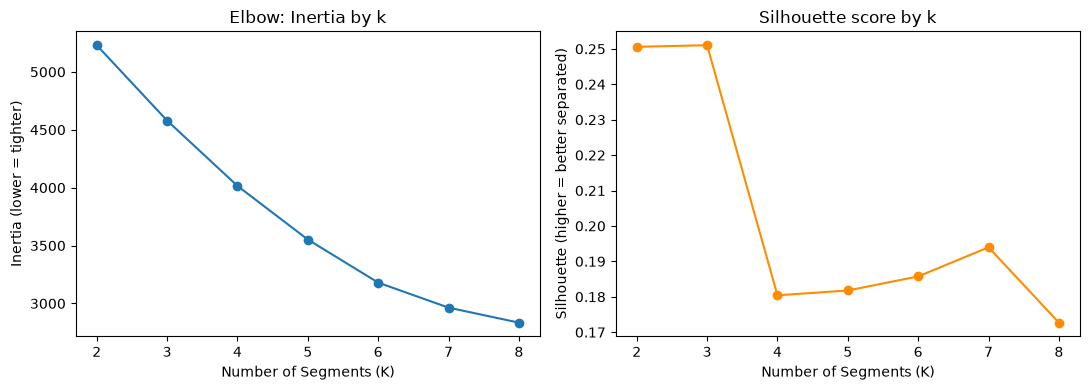

In [10]:
# Plot the Elbow and Silhouette 

fig, (ax1, ax2) = plt.subplots (1,2, figsize = (11,4))

ax1.plot(k_results["K"], k_results["inertia"], marker="o")
ax1.set(title = "Elbow: Inertia by k", xlabel= "Number of Segments (K)",
        ylabel= "Inertia (lower = tighter)")

ax2.plot(k_results["K"], k_results["silhouette"], marker ="o",
         color= "darkorange")
ax2.set(title = "Silhouette score by k", xlabel = "Number of Segments (K)", 
        ylabel = "Silhouette (higher = better separated)")

plt.tight_layout()
plt.savefig(FIGURES / "elbow_silhouette.png", dpi=150, bbox_inches="tight")
plt.show()

## Choosing k
- Silhouette is highest at k = 2–3 (~0.25) and drops to ~0.18 at k = 4.
- Inertia falls steadily with no sharp elbow, which is common with customer data.
- Choosing **k = 4**: it separates a distinct Loyal Veterans group (11 yrs tenure, 92% renewal)
  that k = 3 blends together. That trades a little separation for segments the
  retention team can act on.
- Silhouette below 0.3 means segments overlap, so they guide targeting rather than act as hard boundaries.

In [11]:
# Fit K4 and Profile

kmeans = KMeans(n_clusters=4, n_init=10, random_state=42)
model_df["segment"] = kmeans.fit_predict(X_Scaled)

segment_profile = model_df.groupby("segment")[cluster_features + ["renewed"]].mean().round(2)
segment_profile["accounts"] = model_df["segment"].value_counts().sort_index()
segment_profile["corporate_share"] = (model_df
                                      .assign(is_corporate=model_df["Account_Type"] == "Corporate")
                                      .groupby("segment")["is_corporate"].mean()
                                      .round(2))
segment_profile

,resale_rate,forward_rate,no_show_rate,concerts_bought,tenure_years,Price_Per_Seat,Num_Seats,renewed,accounts,corporate_share
segment,,,,,,,,,,
0,0.01,0.09,0.22,0.11,3.38,371.74,3.08,0.82,477,0.09
1,0.01,0.08,0.19,2.54,4.80,374.40,3.26,0.84,104,0.12
2,0.00,0.08,0.09,0.09,11.01,283.31,3.06,0.92,213,0.06
3,0.21,0.15,0.40,0.57,4.43,341.95,4.23,0.63,94,0.52


In [12]:
segment_names = {0: "Newer Core Members",
                 1: "Concert Add-On Fans",
                 2: "Loyal Veterans",
                 3: "Resellers & Absentees"}
model_df["segment_name"] = model_df["segment"].map(segment_names)


model_df["segment_name"].value_counts()

segment_name
Newer Core Members       477
Loyal Veterans           213
Concert Add-On Fans      104
Resellers & Absentees     94
Name: count, dtype: int64

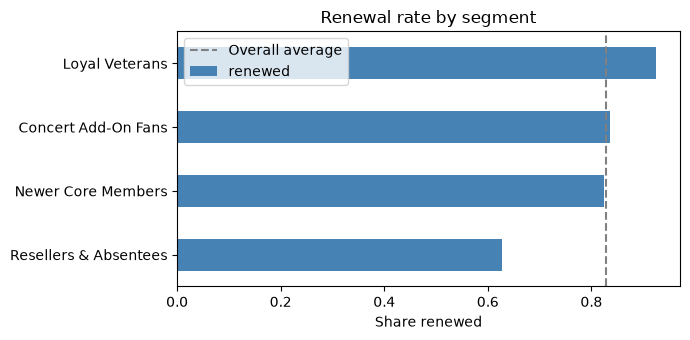

segment_name
Resellers & Absentees    0.628
Newer Core Members       0.824
Concert Add-On Fans      0.837
Loyal Veterans           0.925
Name: renewed, dtype: float64

In [13]:
# Renewal rate by segment
renewal_by_segment = model_df.groupby("segment_name")["renewed"].mean().sort_values()

ax = renewal_by_segment.plot(kind="barh", figsize=(7, 3.5), color="steelblue")
ax.set(title="Renewal rate by segment", xlabel="Share renewed", ylabel="")
ax.axvline(model_df["renewed"].mean(), color="gray", linestyle="--", label="Overall average")
ax.legend()
plt.tight_layout()
plt.savefig(FIGURES / "renewal_by_segment.png", dpi=150, bbox_inches="tight")
plt.show()

renewal_by_segment.round(3)

In [14]:
# Turn the messy Location column into a 2-letter state
def location_to_state(location):
    """Turn any Location format into a 2-letter state code."""
    if pd.isna(location):
        return "Unknown"
    text = str(location).upper().replace(",", " ").strip()   # "Brooklyn, NY" -> "BROOKLYN  NY"

    # 1. NYC nicknames
    if text in ("NYC", "NEW YORK CITY", "MANHATTAN") or text.startswith("MANHATTAN"):
        return "NY"
    # 2. Full state names at the end
    full_names = {"NEW YORK": "NY", "NEW JERSEY": "NJ", "PENNSYLVANIA": "PA", "VERMONT": "VT"}
    for name, code in full_names.items():
        if text.endswith(name):
            return code
    # 3. A 2-letter state code as one of the words
    words = text.split()
    for code in ("NY", "NJ", "PA", "VT"):
        if code in words:
            return code
    # 4. ZIP code only: the first 3 digits identify the state
    if text.isdigit():
        zip3 = int(text[:3])
        if 100 <= zip3 <= 149: return "NY"
        if 150 <= zip3 <= 196: return "PA"
        if 70 <= zip3 <= 89:   return "NJ"
        if 50 <= zip3 <= 59:   return "VT"
    return "Unknown"

model_df["State"] = model_df["Location"].apply(location_to_state)
model_df["State"].value_counts()

State
NY         618
NJ         144
Unknown     66
PA          44
VT          16
Name: count, dtype: int64

In [15]:
# Where do members in each segment live? (share within each segment)
pd.crosstab(model_df["segment_name"], model_df["State"], normalize="index").round(2)

State,NJ,NY,PA,Unknown,VT
segment_name,,,,,
Concert Add-On Fans,0.14,0.72,0.04,0.08,0.02
Loyal Veterans,0.19,0.70,0.03,0.08,0.00
Newer Core Members,0.16,0.71,0.04,0.08,0.01
Resellers & Absentees,0.12,0.57,0.17,0.04,0.10


In [16]:
# Does age differ by segment?
model_df.groupby("segment_name")["Age"].mean().round(1)

segment_name
Concert Add-On Fans      46.3
Loyal Veterans           44.8
Newer Core Members       45.3
Resellers & Absentees    47.5
Name: Age, dtype: float64

## Segmentation Findings (k = 4)

| Segment | Accounts | Defining behavior | Renewed |
|---|---|---|---|
| Loyal Veterans | 213 | ~11 yrs tenure, lowest no-show (9%) | 92% |
| Concert Add-On Fans | 104 | ~2.5 concerts each | 84% |
| Newer Core Members | 477 | ~3 yrs tenure, average behavior | 82% |
| Resellers & Absentees | 94 | 21% resold, 40% no-show, 52% corporate | 63% |

- **Renewal gap:** Loyal Veterans renew at 92% vs. 63% for Resellers & Absentees,
  a 29-point gap found without the model ever seeing renewal.
- **Distance matters:** 27% of Resellers & Absentees live in PA or VT, vs. 3–5% in
  other segments. Living far from MSG likely drives skipped and resold games.
- **Age doesn't separate behavior:** average age is 45–48 in every segment.
- **So what:** retention outreach should focus on Resellers & Absentees, especially
  corporate and long-distance accounts, before renewal season.
- Segments were built on behavior only. Location and age were profiled afterward.

In [17]:
# Save model_df with segment labels and State for the renewal model
model_df.to_csv(PROCESSED_DATA / "model_df.csv", index=False)

# Confirm the new columns are there
print([c for c in ["segment", "segment_name", "State"] if c in model_df.columns])

['segment', 'segment_name', 'State']
